In [1]:
!pip install git+https://github.com/facebookresearch/segment-anything-2.git -q

!wget -qO sam2_hiera_tiny.pt https://dl.fbaipublicfiles.com/segment_anything_2/072824/sam2_hiera_tiny.pt

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Using: cuda


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


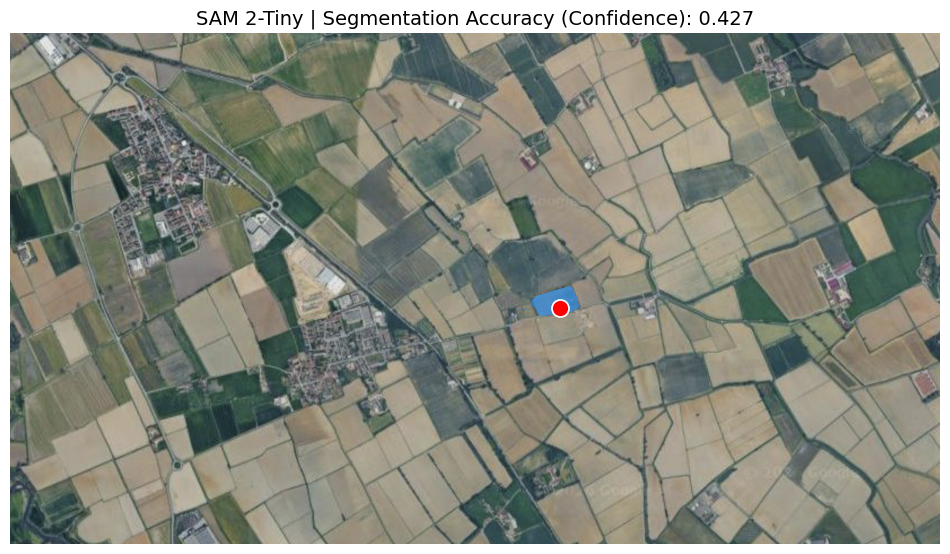

In [2]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using: {device}")

sam2_checkpoint = "sam2_hiera_tiny.pt"
model_cfg = "sam2_hiera_t.yaml"

sam2_model = build_sam2(model_cfg, sam2_checkpoint, device=device)
predictor = SAM2ImagePredictor(sam2_model)

image_path = '/content/test_title_2.png'
image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

predictor.set_image(image_rgb)

input_point = np.array([[1200, 600]])
input_label = np.array([1])

masks, scores, logits = predictor.predict(
    point_coords=input_point,
    point_labels=input_label,
    multimask_output=False,
)

def show_mask(mask, ax, random_color=False):
    if random_color:
        color = np.concatenate([np.random.random(3), np.array([0.6])], axis=0)
    else:
        color = np.array([30/255, 144/255, 255/255, 0.6])
    h, w = mask.shape[-2:]
    mask_image = mask.reshape(h, w, 1) * color.reshape(1, 1, -1)
    ax.imshow(mask_image)

def show_points(coords, labels, ax, marker_size=150):
    pos_points = coords[labels==1]
    ax.scatter(pos_points[:, 0], pos_points[:, 1], color='red', marker='o', s=marker_size, edgecolor='white', linewidth=1.25)

plt.figure(figsize=(12, 12))
plt.imshow(image_rgb)
show_mask(masks[0], plt.gca())
show_points(input_point, input_label, plt.gca())
plt.title(f"SAM 2-Tiny | Segmentation Accuracy (Confidence): {scores[0]:.3f}", fontsize=14)
plt.axis('off')
plt.show()